# Dinamika Pertumbuhan Tanaman Hidroponik
### Pemodelan Sistem Dinamik dengan Python (TA-06 · Modul Praktikum 6 · Pemodelan dan Simulasi)

Notebook ini memodelkan **pertumbuhan tanaman selada pada sistem hidroponik (reservoir 20 L)** sebagai sistem dinamik
dua *stock*: **biomassa kering tanaman** `B(t)` dan **konsentrasi nutrisi di reservoir** `N(t)`.
Input kontrol adalah **laju dosis nutrisi** `u(t)` dari pompa dosis.

Isi notebook: (1) parameter, (2) persamaan model, (3) perhitungan manual, (4) diagram stock-flow,
(5) steady state, (6) simulasi input **step, impulse, ramp, sinusoidal**, (7) perbandingan dan validasi numerik.

> Semua parameter bersifat **sintetis** (orde besar realistis untuk selada NFT) dan dapat dikalibrasi dengan data eksperimen.
> Satuan waktu: **hari**. Hanya memerlukan `numpy` dan `matplotlib` (sudah tersedia di Google Colab).

In [1]:
"""
Dinamika Pertumbuhan Tanaman Hidroponik - Simulasi Sistem Dinamik
TA-06 / Modul Praktikum 6 - Pemodelan dan Simulasi

Model (ODE, metode Euler maju):
    mu(N)  = mu_max * N / (Ks + N)                  (kinetika Monod)
    dB/dt  = mu(N) * B * (1 - B/B_max)               (pertumbuhan logistik terbatas nutrisi)
    dN/dt  = u(t)/V - (1/(Y*V)) * dB/dt - kd * N     (neraca massa nutrisi)
"""
import os
from dataclasses import dataclass

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Ellipse, Polygon

FIG_DIR = "figures"
OUT_DIR = "output"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

WARNA = {
    "biomassa": "#2E7D32",   # hijau
    "nutrisi": "#1565C0",    # biru
    "input": "#D84315",      # oranye-merah
    "steady": "#6A1B9A",     # ungu
    "referensi": "#757575",  # abu-abu
}
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 10.5, "legend.fontsize": 9,
})

## 1. Parameter dan Dataset Sintetis

| Simbol | Arti | Nilai | Satuan |
|---|---|---|---|
| `mu_max` | laju pertumbuhan spesifik maksimum | 0.35 | 1/hari |
| `Ks` | konstanta setengah-jenuh Monod | 50 | mg/L |
| `B_max` | kapasitas biomassa maksimum sistem (12 tanaman) | 50 | g bobot kering |
| `Y` | koefisien yield (biomassa per nutrisi terserap) | 0.04 | g/mg |
| `V` | volume reservoir | 20 | L |
| `kd` | laju kehilangan nutrisi (pengendapan/degradasi) | 0.02 | 1/hari |
| `B0`, `N0` | kondisi awal biomassa dan nutrisi | 0.5 ; 80 | g ; mg/L |
| `u0` | dosis nutrisi dasar (nominal) | 30 | mg/hari |
| `dt` | langkah waktu Euler | 1 | hari |

In [2]:
@dataclass(frozen=True)
class Params:
    # --- parameter model ---
    mu_max: float = 0.35      # 1/hari
    Ks: float = 50.0          # mg/L
    B_max: float = 50.0       # g
    Y: float = 0.04           # g biomassa per mg nutrisi
    V: float = 20.0           # L
    kd: float = 0.02          # 1/hari
    # --- kondisi awal & input nominal ---
    B0: float = 0.5           # g
    N0: float = 80.0          # mg/L
    u0: float = 30.0          # mg/hari
    # --- pengaturan simulasi ---
    dt: float = 1.0           # hari
    t_end: float = 60.0       # hari
    # --- parameter sinyal uji (diterapkan pada u(t)) ---
    t_pemicu: float = 20.0    # hari, waktu sinyal uji dimulai
    step_amp: float = 30.0    # mg/hari  (u: 30 -> 60)
    impulse_M: float = 200.0  # mg       (dosis kejut satu kali)
    ramp_slope: float = 1.0   # mg/hari^2
    sin_amp: float = 15.0     # mg/hari
    sin_periode: float = 10.0 # hari

P = Params()

In [3]:
print(P)

Params(mu_max=0.35, Ks=50.0, B_max=50.0, Y=0.04, V=20.0, kd=0.02, B0=0.5, N0=80.0, u0=30.0, dt=1.0, t_end=60.0, t_pemicu=20.0, step_amp=30.0, impulse_M=200.0, ramp_slope=1.0, sin_amp=15.0, sin_periode=10.0)


## 2. Persamaan Model

Sistem dimodelkan sebagai **ODE** (tidak bergantung ruang karena reservoir dianggap tercampur sempurna):

$$\mu(N)=\mu_{max}\frac{N}{K_s+N}$$

$$\frac{dB}{dt}=\mu(N)\,B\left(1-\frac{B}{B_{max}}\right)$$

$$\frac{dN}{dt}=\frac{u(t)}{V}-\frac{1}{Y\,V}\frac{dB}{dt}-k_d\,N$$

Suku kedua pada persamaan nutrisi adalah **penyerapan nutrisi** oleh tanaman yang sebanding dengan pertumbuhan biomassa.
Dengan metode Euler maju: $B_{k+1}=B_k+\dot B_k\,\Delta t$ dan $N_{k+1}=N_k+\dot N_k\,\Delta t$.

In [4]:
def mu_monod(N, p=P):
    """Laju pertumbuhan spesifik (1/hari), kinetika Monod."""
    return p.mu_max * N / (p.Ks + N)


def turunan(B, N, u, p=P):
    """Mengembalikan (dB/dt [g/hari], dN/dt [mg/L/hari])."""
    mu = mu_monod(N, p)
    dBdt = mu * B * (1.0 - B / p.B_max)
    dNdt = u / p.V - dBdt / (p.Y * p.V) - p.kd * N
    return dBdt, dNdt


def simulasi(sinyal_u, p=P, t_end=None, dt=None, B0=None, N0=None):
    """Simulasi Euler maju. sinyal_u: fungsi t -> u(t) [mg/hari]."""
    t_end = p.t_end if t_end is None else t_end
    dt = p.dt if dt is None else dt
    B0 = p.B0 if B0 is None else B0
    N0 = p.N0 if N0 is None else N0
    n = int(round(t_end / dt))
    t = np.arange(n + 1) * dt
    u = np.array([sinyal_u(tk) for tk in t])
    B = np.zeros(n + 1)
    N = np.zeros(n + 1)
    B[0], N[0] = B0, N0
    for k in range(n):
        dBdt, dNdt = turunan(B[k], N[k], u[k], p)
        B[k + 1] = B[k] + dBdt * dt
        N[k + 1] = max(N[k] + dNdt * dt, 0.0)   # konsentrasi tidak boleh negatif
    return {"t": t, "u": u, "B": B, "N": N, "dt": dt}

## 3. Sinyal Input (Kontrol Dosis Nutrisi)

Semua sinyal uji ditambahkan pada dosis dasar `u0` mulai `t_pemicu = 20` hari:

| Skenario | Bentuk $u(t)$ |
|---|---|
| Step | $u_0 + 30$ untuk $t \ge 20$ |
| Impulse | $u_0 + M/\Delta t$ pada satu langkah di $t=20$ (dosis kejut $M=200$ mg) |
| Ramp | $u_0 + 1.0\,(t-20)$ untuk $t \ge 20$ |
| Sinusoidal | $u_0 + 15\sin(2\pi t/10)$ |

In [5]:
SKENARIO = {
    "baseline":    {"judul": "Baseline: dosis konstan u0 = 30 mg/hari", "warna": "#757575"},
    "tanpa_dosis": {"judul": "Tanpa dosis nutrisi (u = 0)",             "warna": "#000000"},
    "step":        {"judul": "Input Step: u naik 30 -> 60 mg/hari pada t = 20 hari", "warna": "#EF6C00"},
    "impulse":     {"judul": "Input Impulse: dosis kejut 200 mg pada t = 20 hari",   "warna": "#6A1B9A"},
    "ramp":        {"judul": "Input Ramp: u naik 1 mg/hari per hari mulai t = 20",   "warna": "#00897B"},
    "sinus":       {"judul": "Input Sinusoidal: u = 30 + 15 sin(2*pi*t/10)",         "warna": "#C2185B"},
}


def buat_sinyal(nama, p=P):
    """Mengembalikan fungsi u(t) [mg/hari] untuk skenario `nama`."""
    if nama == "baseline":
        return lambda t: p.u0
    if nama == "tanpa_dosis":
        return lambda t: 0.0
    if nama == "step":
        return lambda t: p.u0 + (p.step_amp if t >= p.t_pemicu else 0.0)
    if nama == "impulse":   # pulsa satu langkah dengan luas M (mg) -> tinggi M/dt
        return lambda t: p.u0 + (p.impulse_M / p.dt if abs(t - p.t_pemicu) < p.dt / 2 else 0.0)
    if nama == "ramp":
        return lambda t: p.u0 + (p.ramp_slope * (t - p.t_pemicu) if t >= p.t_pemicu else 0.0)
    if nama == "sinus":
        return lambda t: p.u0 + p.sin_amp * np.sin(2 * np.pi * t / p.sin_periode)
    raise ValueError(f"Skenario tidak dikenal: {nama}")

## 4. Analisis Steady State, Kestabilan, dan Derajat Kebebasan

Pada steady state $dB/dt=dN/dt=0$:

- $dB/dt=0 \Rightarrow B=0$ atau $B=B_{max}$ (atau $N=0$).
- Untuk $B=B_{max}$: $dN/dt=0 \Rightarrow \dfrac{u_0}{V}-k_dN=0 \Rightarrow N^*=\dfrac{u_0}{k_d V}$.

Kestabilan ditentukan dari eigenvalue matriks Jacobian di titik setimbang.
**DOF:** 3 variabel tak diketahui $(B,N,\mu)$ dan 3 persamaan $\Rightarrow$ DOF $=0$ (sistem terdefinisi penuh bila $u(t)$ diberikan).

In [6]:
def steady_state(u0, p=P):
    """Titik setimbang tanaman hidup: B* = B_max, N* = u0/(kd*V)."""
    return p.B_max, u0 / (p.kd * p.V)


def jacobian(B, N, p=P):
    """Matriks Jacobian analitik dari [dB/dt, dN/dt] terhadap [B, N]."""
    mu = mu_monod(N, p)
    dmu = p.mu_max * p.Ks / (p.Ks + N) ** 2
    a11 = mu * (1 - 2 * B / p.B_max)
    a12 = dmu * B * (1 - B / p.B_max)
    a21 = -a11 / (p.Y * p.V)
    a22 = -a12 / (p.Y * p.V) - p.kd
    return np.array([[a11, a12], [a21, a22]])


def analisis_kestabilan(p=P):
    Bss, Nss = steady_state(p.u0, p)
    eig_hidup = np.linalg.eigvals(jacobian(Bss, Nss, p))
    eig_nol = np.linalg.eigvals(jacobian(0.0, p.N0, p))   # titik B = 0 (tanaman tidak ada)
    return {"B_ss": Bss, "N_ss": Nss, "eig_hidup": eig_hidup, "eig_B0": eig_nol,
            "tau": 1.0 / np.abs(eig_hidup.real)}


def cetak_kestabilan(p=P):
    ks = analisis_kestabilan(p)
    print(f"Steady state        : B* = {ks['B_ss']:.2f} g, N* = {ks['N_ss']:.2f} mg/L")
    print(f"Eigenvalue (B*,N*)  : {np.round(ks['eig_hidup'], 4)}  -> stabil (semua negatif)")
    print(f"Konstanta waktu     : {np.round(ks['tau'], 2)} hari")
    print(f"Eigenvalue (B=0)    : {np.round(ks['eig_B0'], 4)}  -> tidak stabil (ada yang positif)")
    print("DOF = 3 persamaan - 3 variabel tak diketahui (B, N, mu) = 0")
    return ks

In [7]:
ks = cetak_kestabilan(P)

Steady state        : B* = 50.00 g, N* = 75.00 mg/L
Eigenvalue (B*,N*)  : [-0.02+0.j -0.21+0.j]  -> stabil (semua negatif)
Konstanta waktu     : [50.    4.76] hari
Eigenvalue (B=0)    : [-0.02  +0.j  0.2154+0.j]  -> tidak stabil (ada yang positif)
DOF = 3 persamaan - 3 variabel tak diketahui (B, N, mu) = 0


In [8]:
def tampilkan(fig, nama):
    """Simpan gambar ke folder figures/ lalu tampilkan (di Colab/Jupyter) atau tutup (mode skrip)."""
    fig.savefig(os.path.join(FIG_DIR, nama + ".png"), dpi=150, bbox_inches="tight")
    if matplotlib.get_backend().lower() in ("agg", "pdf", "svg", "ps", "cairo", "template"):
        plt.close(fig)
    else:
        plt.show()

## 5. Perhitungan Manual (Euler, Δt = 1 hari)

Dihitung tangan untuk 5 langkah pertama (kondisi baseline, $u=u_0=30$ mg/hari). Fungsi berikut mencetak tabel yang
sama sehingga hasil hitung tangan bisa dicocokkan dengan program.

In [9]:
def tabel_manual(p=P, n=5):
    """Tabel perhitungan manual Euler untuk n langkah pertama (kondisi baseline)."""
    res = simulasi(buat_sinyal("baseline", p), p, t_end=n * p.dt)
    baris = []
    for k in range(n):
        B, N, u = res["B"][k], res["N"][k], res["u"][k]
        dBdt, dNdt = turunan(B, N, u, p)
        baris.append({"t": res["t"][k], "B": B, "N": N, "mu": mu_monod(N, p),
                      "dBdt": dBdt, "dNdt": dNdt,
                      "B_next": res["B"][k + 1], "N_next": res["N"][k + 1]})
    return baris


def cetak_tabel_manual(p=P, n=5):
    baris = tabel_manual(p, n)
    print(f"{'t':>3} {'B':>8} {'N':>8} {'mu(N)':>8} {'dB/dt':>9} {'dN/dt':>9} {'B(t+1)':>9} {'N(t+1)':>9}")
    for r in baris:
        print(f"{r['t']:3.0f} {r['B']:8.4f} {r['N']:8.4f} {r['mu']:8.4f} {r['dBdt']:9.4f} "
              f"{r['dNdt']:9.4f} {r['B_next']:9.4f} {r['N_next']:9.4f}")
    return baris

In [10]:
baris_manual = cetak_tabel_manual(P)

  t        B        N    mu(N)     dB/dt     dN/dt    B(t+1)    N(t+1)
  0   0.5000  80.0000   0.2154    0.1066   -0.2333    0.6066   79.7667
  1   0.6066  79.7667   0.2151    0.1289   -0.2565    0.7355   79.5102
  2   0.7355  79.5102   0.2149    0.1557   -0.2849    0.8913   79.2254
  3   0.8913  79.2254   0.2146    0.1878   -0.3193    1.0791   78.9061
  4   1.0791  78.9061   0.2142    0.2262   -0.3609    1.3053   78.5452


## 6. Diagram Sistem (Stock-Flow)

In [11]:
def gambar_diagram(p=P):
    """Diagram stock-flow sistem hidroponik dengan semua variabel berlabel."""
    fig, ax = plt.subplots(figsize=(8.8, 6.6))
    ax.set_xlim(0, 8.8); ax.set_ylim(0, 6.6); ax.axis("off"); ax.grid(False)

    def kotak(x, y, w, h, teks, fc, ec, fs=9.5):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12",
                                    fc=fc, ec=ec, lw=2.0))
        ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", fontsize=fs,
                fontweight="bold", color="#202020")

    def panah(p1, p2, warna="#333333", ls="-", lw=2.2, rad=0.0, ms=16):
        ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=ms, color=warna,
                                     lw=lw, linestyle=ls, connectionstyle=f"arc3,rad={rad}"))

    def katup(x, y, warna, s=0.15):
        ax.add_patch(Polygon([(x - s, y + s * .95), (x - s, y - s * .95), (x, y)], fc=warna, ec=warna))
        ax.add_patch(Polygon([(x + s, y + s * .95), (x + s, y - s * .95), (x, y)], fc=warna, ec=warna))

    def elips(x, y, w, h, teks, fc, ec, fs=9):
        ax.add_patch(Ellipse((x, y), w, h, fc=fc, ec=ec, lw=1.6, ls="--"))
        ax.text(x, y, teks, ha="center", va="center", fontsize=fs, color="#202020")

    ax.text(4.4, 6.32, "Diagram Stock-Flow Sistem Hidroponik (Selada NFT, Reservoir 20 L)",
            ha="center", fontsize=11.5, fontweight="bold")

    # --- stock dan sumber kontrol ---
    kotak(0.1, 3.15, 1.75, 1.1, "POMPA DOSIS\nInput kontrol\nu(t) [mg/hari]", "#FFE0B2", WARNA["input"], fs=9)
    kotak(2.7, 3.0, 2.5, 1.4, "STOCK  N(t)\nKonsentrasi nutrisi\nreservoir [mg/L]", "#BBDEFB", WARNA["nutrisi"])
    kotak(6.55, 3.0, 2.15, 1.4, "STOCK  B(t)\nBiomassa kering\ntanaman [g]", "#C8E6C9", WARNA["biomassa"])
    ax.text(2.75, 2.8, f"V = {p.V:g} L", ha="left", fontsize=8.5, color="#444")

    # --- aliran (flow) ---
    panah((1.9, 3.7), (2.66, 3.7), WARNA["input"]); katup(2.28, 3.7, WARNA["input"])
    ax.text(2.28, 4.12, "inflow\n$u(t)/V$", ha="center", fontsize=8.5, color=WARNA["input"])

    panah((5.25, 3.7), (6.5, 3.7), WARNA["biomassa"]); katup(5.87, 3.7, WARNA["biomassa"])
    ax.text(5.87, 3.28, "pertumbuhan\n$\\mu(N)\\,B\\,(1-B/B_{max})$\n[g/hari]", ha="center", va="center",
            fontsize=8, color=WARNA["biomassa"])

    panah((3.95, 2.95), (3.95, 1.58), WARNA["nutrisi"]); katup(3.95, 2.3, WARNA["nutrisi"])
    ax.add_patch(Ellipse((3.95, 1.28), 1.5, 0.6, fc="#ECEFF1", ec="#607D8B", lw=1.6))
    ax.text(3.95, 1.28, "sink", ha="center", va="center", fontsize=9, color="#455A64")
    ax.text(3.75, 2.3, "outflow kehilangan nutrisi\n$k_d\\,N$ (pengendapan/degradasi)", ha="right", va="center",
            fontsize=8.5, color=WARNA["nutrisi"])

    # --- penyerapan nutrisi (umpan balik B -> N) ---
    panah((7.6, 2.95), (4.9, 2.95), WARNA["nutrisi"], ls="--", lw=1.6, rad=-0.35, ms=14)
    ax.text(6.25, 1.95, "penyerapan nutrisi\n$\\frac{1}{Y\\,V}\\,\\frac{dB}{dt}$ (mengurangi N)",
            ha="center", va="center", fontsize=8.5, color=WARNA["nutrisi"])

    # --- variabel bantu ---
    elips(3.95, 5.5, 3.0, 0.9, "$\\mu(N)=\\mu_{max}\\,N/(K_s+N)$\n(kinetika Monod)", "#F3E5F5", WARNA["steady"])
    elips(7.45, 5.5, 2.6, 0.9, "$(1-B/B_{max})$\n(batas kapasitas)", "#FFF9C4", "#F9A825")
    panah((3.8, 4.45), (3.8, 5.05), "#555", ls="--", lw=1.4, ms=12)      # N -> mu
    panah((5.2, 5.2), (5.8, 3.95), "#555", ls="--", lw=1.4, ms=12)       # mu -> flow
    panah((7.6, 4.45), (7.6, 5.05), "#555", ls="--", lw=1.4, ms=12)      # B -> kapasitas
    panah((6.5, 5.15), (5.95, 3.95), "#555", ls="--", lw=1.4, ms=12)     # kapasitas -> flow

    # --- loop umpan balik ---
    ax.text(0.1, 1.85,
            "Struktur umpan balik:\n"
            "R  : B naik -> pertumbuhan naik\n"
            "       -> B naik (reinforcing)\n"
            "B1 : B mendekati B_max\n"
            "       -> (1-B/B_max) turun\n"
            "       -> pertumbuhan melambat\n"
            "B2 : B naik -> N terserap -> N turun\n"
            "       -> mu(N) turun (balancing)",
            fontsize=8, va="top", bbox=dict(boxstyle="round", fc="#FAFAFA", ec="#9E9E9E"))
    ax.text(8.7, 0.1,
            f"Parameter:\nmu_max={p.mu_max:g}/hari, Ks={p.Ks:g} mg/L, B_max={p.B_max:g} g,\n"
            f"Y={p.Y:g} g/mg, kd={p.kd:g}/hari\n"
            "Garis tebal = aliran material\nGaris putus-putus = pengaruh informasi",
            ha="right", fontsize=8, color="#333",
            bbox=dict(boxstyle="round", fc="#FAFAFA", ec="#9E9E9E"))
    return fig

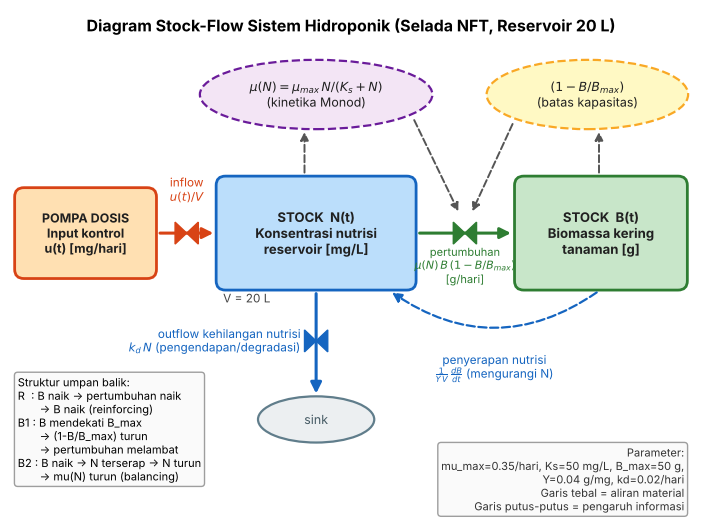

In [12]:
tampilkan(gambar_diagram(P), "01_diagram_stock_flow")

## 7. Simulasi Steady State

Simulasi dijalankan 300 hari dengan dosis konstan $u_0$ agar sistem mencapai keseimbangan. Sebagai pembuktian,
simulasi kedua dimulai **tepat di titik steady state** — kurvanya harus datar. Potret fase menunjukkan berbagai
kondisi awal yang semuanya menuju titik setimbang yang sama.

In [13]:
def waktu_settling(t, y, y_ss, tol=0.02):
    """Waktu terakhir saat |y - y_ss| > tol*|y_ss| (waktu mapan dalam pita +-2%)."""
    di_luar = np.where(np.abs(y - y_ss) > tol * abs(y_ss))[0]
    return t[di_luar[-1] + 1] if len(di_luar) and di_luar[-1] + 1 < len(t) else (t[0] if not len(di_luar) else np.nan)


def plot_steady_state(res, res0, p=P):
    Bss, Nss = steady_state(p.u0, p)
    fig, ax = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    ax[0].plot(res["t"], res["B"], color=WARNA["biomassa"], lw=2.4, label="B(t) dari B0 = 0.5 g")
    ax[0].plot(res0["t"], res0["B"], color="#BDBDBD", lw=4, alpha=.8, label="B(t) dimulai di steady state", zorder=0)
    ax[0].axhline(Bss, color=WARNA["steady"], ls="--", lw=1.6, label=f"B* = {Bss:.0f} g")
    ax[0].set_ylabel("Biomassa kering B(t) [g]"); ax[0].legend(loc="center right")
    ax[1].plot(res["t"], res["N"], color=WARNA["nutrisi"], lw=2.4, label="N(t) dari N0 = 80 mg/L")
    ax[1].plot(res0["t"], res0["N"], color="#BDBDBD", lw=4, alpha=.8, label="N(t) dimulai di steady state", zorder=0)
    ax[1].axhline(Nss, color=WARNA["steady"], ls="--", lw=1.6, label=f"N* = u0/(kd*V) = {Nss:.0f} mg/L")
    ax[1].set_ylabel("Konsentrasi nutrisi N(t) [mg/L]"); ax[1].set_xlabel("Waktu (hari)")
    ax[1].legend(loc="lower right")
    fig.suptitle("Simulasi Steady State (u = 30 mg/hari konstan)", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_fase(p=P, t_end=300):
    Bss, Nss = steady_state(p.u0, p)
    fig, ax = plt.subplots(figsize=(8, 6))
    warna = plt.cm.viridis(np.linspace(0.05, 0.9, 9))
    i = 0
    for B0 in (0.5, 10.0, 30.0):
        for N0 in (10.0, 80.0, 150.0):
            r = simulasi(buat_sinyal("baseline", p), p, t_end=t_end, B0=B0, N0=N0)
            ax.plot(r["B"], r["N"], color=warna[i], lw=1.8, alpha=.9)
            ax.plot(r["B"][0], r["N"][0], "o", color=warna[i], ms=6)
            i += 1
    ax.plot(Bss, Nss, "*", color=WARNA["steady"], ms=20, mec="k", label=f"Titik setimbang (B*, N*) = ({Bss:.0f}; {Nss:.0f})")
    ax.plot([], [], "o", color="gray", label="kondisi awal (9 variasi)")
    ax.set_xlabel("Biomassa B [g]"); ax.set_ylabel("Konsentrasi nutrisi N [mg/L]")
    ax.set_title("Potret Fase: semua lintasan menuju titik setimbang stabil", fontweight="bold")
    ax.set_ylim(0, 190)
    ax.legend(loc="upper left")
    fig.tight_layout()
    return fig


def jalankan_steady_state(p=P):
    Bss, Nss = steady_state(p.u0, p)
    base = buat_sinyal("baseline", p)
    res = simulasi(base, p, t_end=300)
    res0 = simulasi(base, p, t_end=300, B0=Bss, N0=Nss)
    print(f"Akhir simulasi 300 hari : B = {res['B'][-1]:.3f} g, N = {res['N'][-1]:.3f} mg/L")
    print(f"Teori steady state      : B* = {Bss:.3f} g, N* = {Nss:.3f} mg/L")
    print(f"Simpangan maksimum jika dimulai di steady state: "
          f"|dB| = {np.max(np.abs(res0['B'] - Bss)):.2e}, |dN| = {np.max(np.abs(res0['N'] - Nss)):.2e}")
    print(f"Waktu mapan (pita 2%)   : B ~ {waktu_settling(res['t'], res['B'], Bss):.0f} hari, "
          f"N ~ {waktu_settling(res['t'], res['N'], Nss):.0f} hari")
    tampilkan(plot_steady_state(res, res0, p), "02_steady_state")
    tampilkan(plot_fase(p), "03_potret_fase")
    return res, res0

Akhir simulasi 300 hari : B = 50.000 g, N = 74.766 mg/L
Teori steady state      : B* = 50.000 g, N* = 75.000 mg/L
Simpangan maksimum jika dimulai di steady state: |dB| = 0.00e+00, |dN| = 0.00e+00
Waktu mapan (pita 2%)   : B ~ 49 hari, N ~ 209 hari


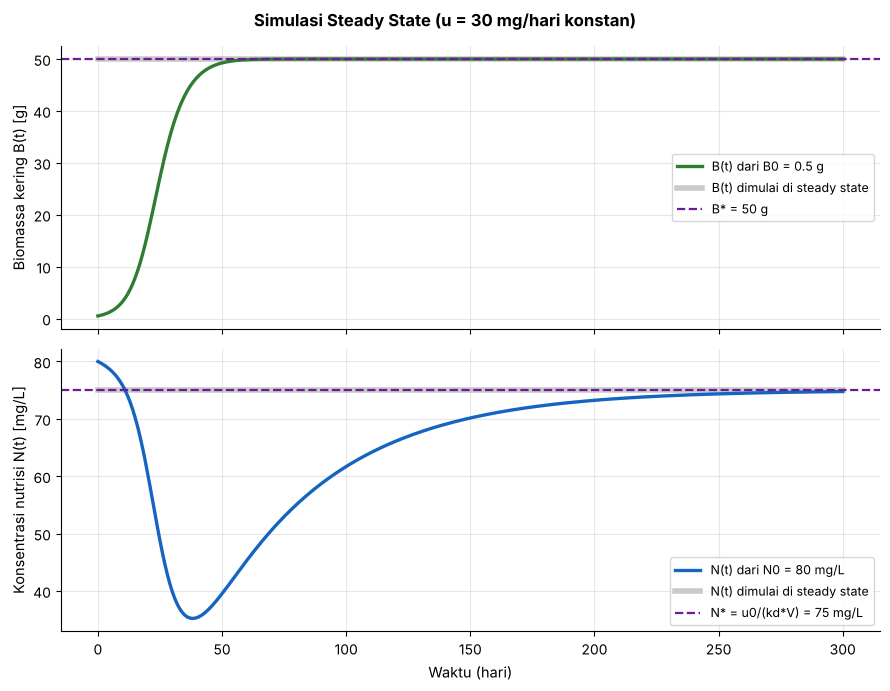

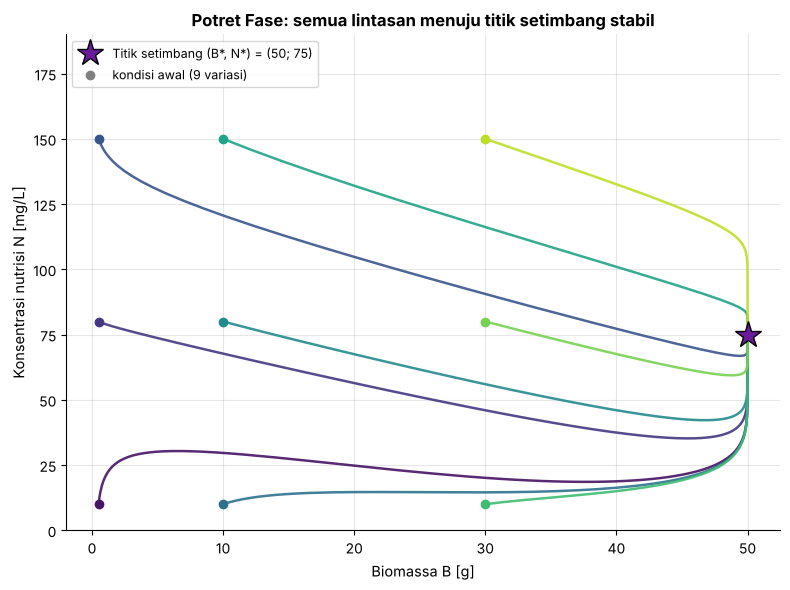

In [14]:
res_ss, res_ss0 = jalankan_steady_state(P)

## 8. Simulasi Respon terhadap Sinyal Kontrol

Fungsi `skenario()` menjalankan satu skenario, menggambar tiga panel (input `u(t)`, nutrisi `N(t)`, biomassa `B(t)`)
dan membandingkannya dengan baseline (garis abu-abu putus-putus).

In [15]:
def plot_skenario(res, nama, base, p=P):
    info = SKENARIO[nama]
    Bss, Nss = steady_state(p.u0, p)
    fig, ax = plt.subplots(3, 1, figsize=(9, 9.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2, 1.2]})
    ax[0].step(base["t"], base["u"], where="post", color=WARNA["referensi"], ls="--", lw=1.3, label="u0 (baseline)")
    if nama in ("ramp", "sinus"):   # kurva kontinu sebagai pembanding hasil diskretisasi
        tt = np.linspace(0, p.t_end, 600)
        sinyal = buat_sinyal(nama, p)
        ax[0].plot(tt, [sinyal(x) for x in tt], color=WARNA["input"], alpha=.35, lw=1.2, label="u(t) kontinu")
    ax[0].step(res["t"], res["u"], where="post", color=WARNA["input"], lw=2.2, label="u(t) diskret (dt = 1 hari)")
    ax[0].set_ylabel("Dosis nutrisi u(t)\n[mg/hari]"); ax[0].legend(loc="upper left")
    ax[1].plot(base["t"], base["N"], color=WARNA["referensi"], ls="--", lw=1.3, label="N(t) baseline")
    ax[1].plot(res["t"], res["N"], color=WARNA["nutrisi"], lw=2.4, label="N(t) skenario")
    ax[1].axhline(Nss, color=WARNA["steady"], ls=":", lw=1.5, label=f"N* = {Nss:.0f} mg/L")
    ax[1].set_ylabel("Nutrisi N(t) [mg/L]"); ax[1].legend(loc="best")
    ax[2].plot(base["t"], base["B"], color=WARNA["referensi"], ls="--", lw=1.3, label="B(t) baseline")
    ax[2].plot(res["t"], res["B"], color=WARNA["biomassa"], lw=2.4, label="B(t) skenario")
    ax[2].axhline(p.B_max, color=WARNA["steady"], ls=":", lw=1.5, label=f"B_max = {p.B_max:.0f} g")
    ax[2].set_ylabel("Biomassa B(t) [g]"); ax[2].set_xlabel("Waktu (hari)"); ax[2].legend(loc="lower right")
    if nama in ("step", "impulse", "ramp"):
        for a in ax:
            a.axvline(p.t_pemicu, color="#9E9E9E", lw=1, ls="-.")
    fig.suptitle(info["judul"], fontweight="bold")
    fig.tight_layout()
    return fig


def skenario(nama, p=P, tampil=True):
    """Jalankan satu skenario; menggambar dan menyimpan grafiknya bila tampil=True."""
    res = simulasi(buat_sinyal(nama, p), p)
    if tampil and nama in ("step", "impulse", "ramp", "sinus"):
        base = simulasi(buat_sinyal("baseline", p), p)
        no = {"step": "04", "impulse": "05", "ramp": "06", "sinus": "07"}[nama]
        tampilkan(plot_skenario(res, nama, base, p), f"{no}_skenario_{nama}")
    return res

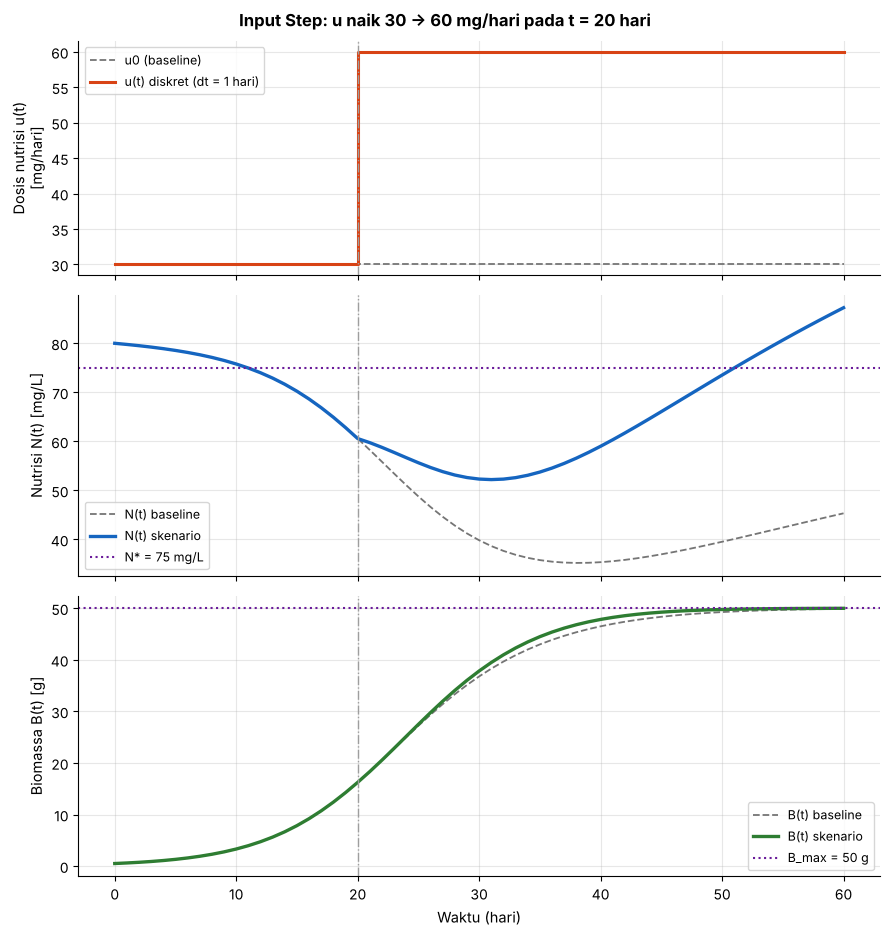

In [16]:
hasil = {"baseline": skenario("baseline", P), "tanpa_dosis": skenario("tanpa_dosis", P)}
hasil["step"] = skenario("step", P)

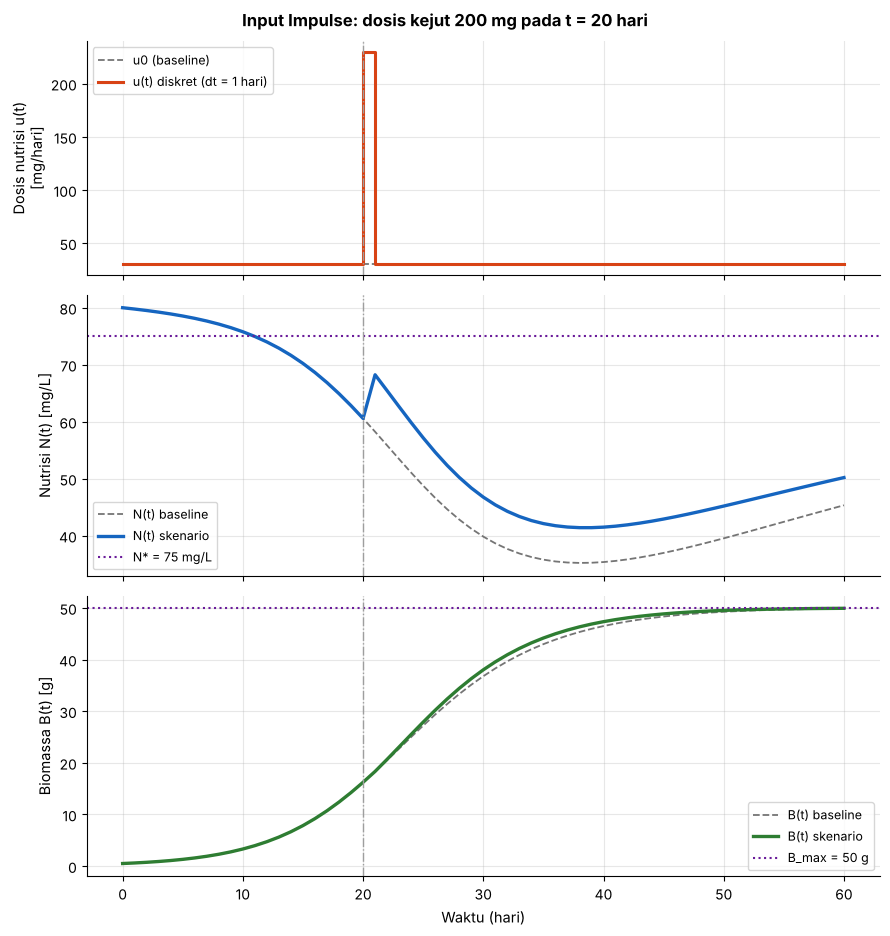

In [17]:
hasil["impulse"] = skenario("impulse", P)

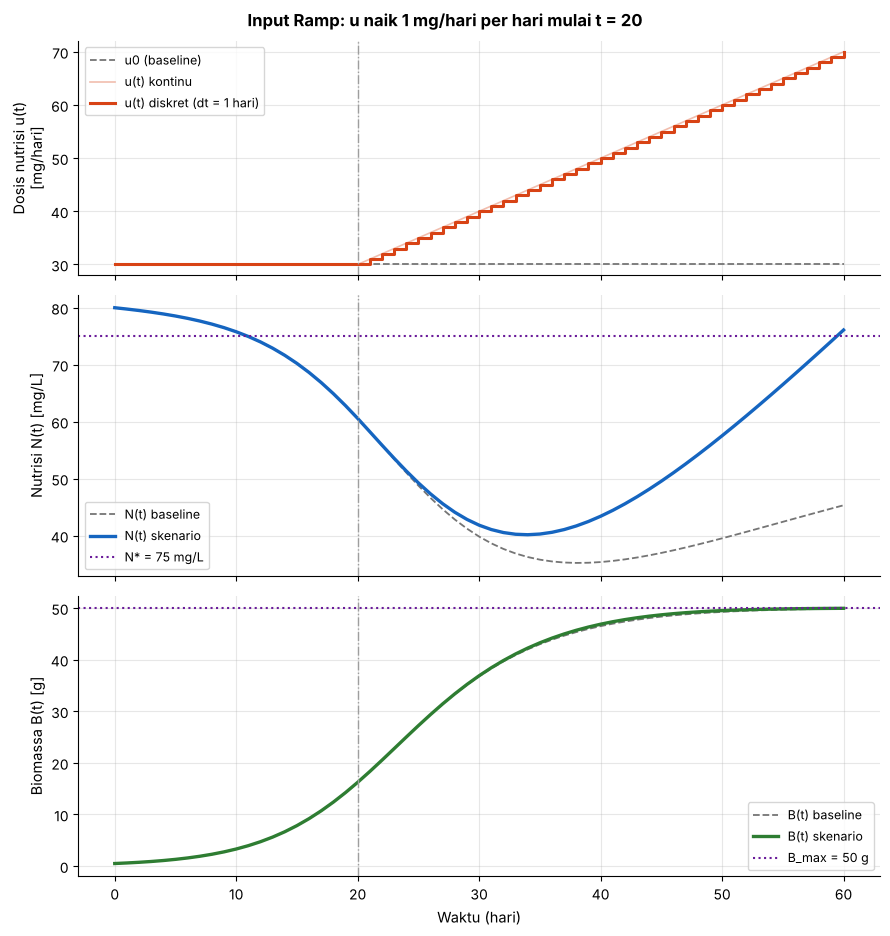

In [18]:
hasil["ramp"] = skenario("ramp", P)

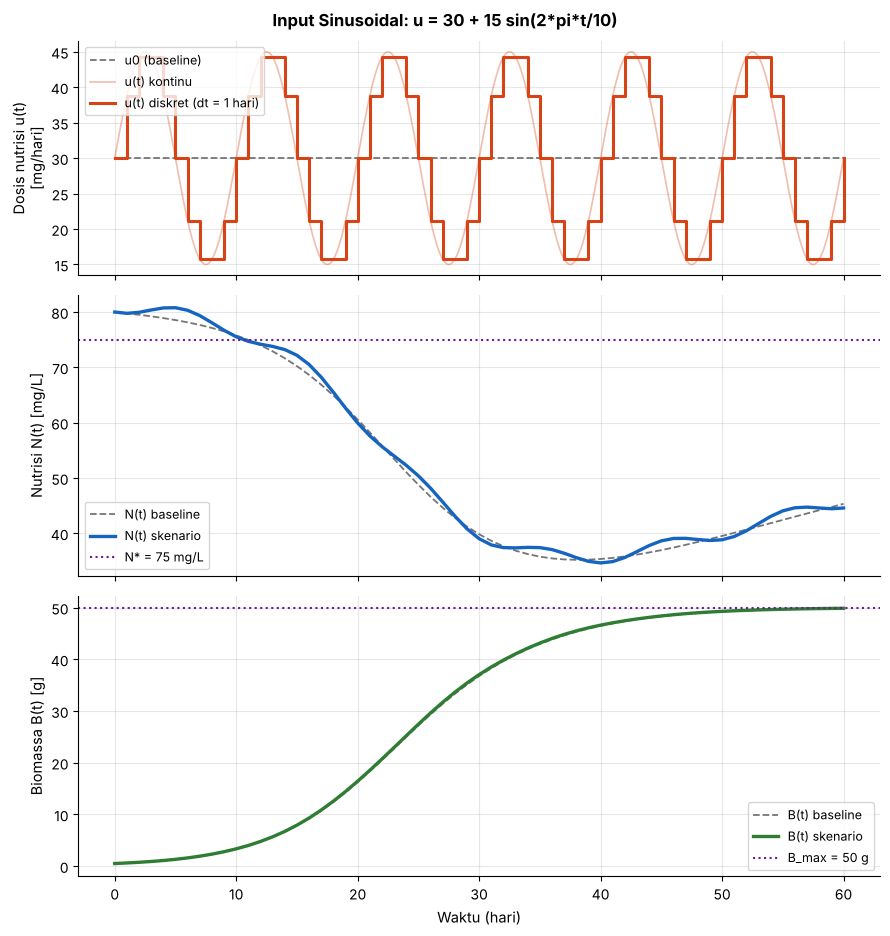

In [19]:
hasil["sinus"] = skenario("sinus", P)

## 9. Perbandingan Skenario dan Ringkasan Metrik

In [20]:
def ringkas(res, p=P):
    t, B, N, u = res["t"], res["B"], res["N"], res["u"]
    def waktu_capai(frac):
        idx = np.where(B >= frac * p.B_max)[0]
        return float(t[idx[0]]) if len(idx) else float("nan")
    return {"B_akhir": float(B[-1]), "t_B50": waktu_capai(0.5), "t_B95": waktu_capai(0.95),
            "N_min": float(N.min()), "N_maks": float(N.max()), "N_akhir": float(N[-1]),
            "dosis_total": float(np.sum(u[:-1]) * res["dt"])}


def plot_perbandingan(hasil, p=P):
    fig, ax = plt.subplots(2, 1, figsize=(9.5, 8.5), sharex=True)
    for nama, res in hasil.items():
        kw = dict(color=SKENARIO[nama]["warna"], lw=2.2,
                  ls="--" if nama == "baseline" else (":" if nama == "tanpa_dosis" else "-"),
                  label=SKENARIO[nama]["judul"].split(":")[0])
        ax[0].plot(res["t"], res["B"], **kw)
        ax[1].plot(res["t"], res["N"], **kw)
    ax[0].axhline(p.B_max, color=WARNA["steady"], ls=":", lw=1.3)
    ax[0].set_ylabel("Biomassa B(t) [g]"); ax[0].legend(loc="lower right", ncol=2)
    ax[1].set_ylabel("Nutrisi N(t) [mg/L]"); ax[1].set_xlabel("Waktu (hari)")
    fig.suptitle("Perbandingan Seluruh Skenario Input", fontweight="bold")
    fig.tight_layout()
    return fig


def bandingkan(hasil, p=P):
    tampilkan(plot_perbandingan(hasil, p), "08_perbandingan_skenario")
    nama_baris = list(hasil.keys())
    kolom = ["B_akhir", "t_B50", "t_B95", "N_min", "N_maks", "N_akhir", "dosis_total"]
    ringkasan = {n: ringkas(hasil[n], p) for n in nama_baris}
    print(f"{'Skenario':<12}" + "".join(f"{k:>12}" for k in kolom))
    for n in nama_baris:
        print(f"{n:<12}" + "".join(f"{ringkasan[n][k]:12.2f}" for k in kolom))
    import csv
    with open(os.path.join(OUT_DIR, "ringkasan_skenario.csv"), "w", newline="") as f:
        w = csv.writer(f); w.writerow(["skenario"] + kolom)
        for n in nama_baris:
            w.writerow([n] + [round(ringkasan[n][k], 4) for k in kolom])
    return ringkasan

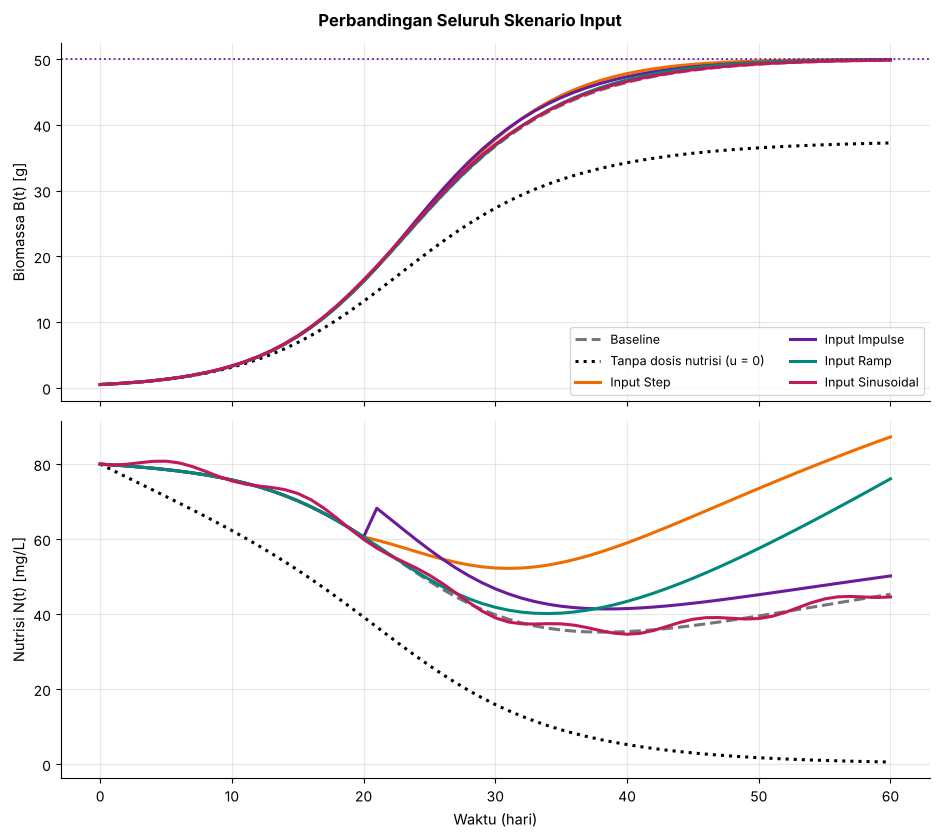

Skenario         B_akhir       t_B50       t_B95       N_min      N_maks     N_akhir dosis_total
baseline           49.87       25.00       43.00       35.21       80.00       45.33     1800.00
tanpa_dosis        37.26       29.00         nan        0.59       80.00        0.59        0.00
step               49.98       24.00       40.00       52.21       87.25       87.25     3000.00
impulse            49.92       24.00       41.00       41.40       80.00       50.19     2000.00
ramp               49.94       24.00       42.00       40.16       80.00       76.09     2580.00
sinus              49.87       24.00       43.00       34.65       80.78       44.58     1800.00


In [21]:
ringkasan = bandingkan(hasil, P)

## 10. Validasi Numerik

Dua pemeriksaan: (a) **konvergensi langkah waktu** — hasil Euler Δt = 1, 0.5, 0.1 hari dibandingkan dengan solusi
referensi Δt = 0.01 hari; (b) **neraca massa nutrisi** — selisih akumulasi nutrisi di reservoir terhadap
(masuk − terserap tanaman − hilang) harus ≈ 0 (galat pembulatan).

In [22]:
def cek_neraca_massa(res, p=P):
    """Residu neraca massa nutrisi [mg]; ~0 bila N tidak terpotong di nol."""
    dt = res["dt"]
    masuk = np.sum(res["u"][:-1]) * dt
    terserap = (res["B"][-1] - res["B"][0]) / p.Y
    hilang = p.kd * p.V * np.sum(res["N"][:-1]) * dt
    akumulasi = p.V * (res["N"][-1] - res["N"][0])
    return float(akumulasi - (masuk - terserap - hilang))


def validasi_langkah_waktu(p=P, daftar_dt=(1.0, 0.5, 0.1), dt_ref=0.01):
    sinyal = buat_sinyal("baseline", p)
    ref = simulasi(sinyal, p, dt=dt_ref)
    hasil_v, galat = {}, []
    for d in daftar_dt:
        r = simulasi(sinyal, p, dt=d)
        idx = np.round(r["t"] / dt_ref).astype(int)
        galat.append((d, float(np.max(np.abs(r["B"] - ref["B"][idx]))),
                      float(np.max(np.abs(r["N"] - ref["N"][idx])))))
        hasil_v[d] = r
    return ref, hasil_v, galat


def plot_validasi(ref, hasil_v):
    warna = ["#E53935", "#FB8C00", "#43A047"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for (d, r), w in zip(hasil_v.items(), warna):
        ax[0].plot(r["t"], r["B"], color=w, lw=2, label=f"Euler dt = {d:g} hari")
        ax[1].plot(r["t"], r["N"], color=w, lw=2, label=f"Euler dt = {d:g} hari")
    ax[0].plot(ref["t"], ref["B"], "k--", lw=1.3, label="Referensi dt = 0.01")
    ax[1].plot(ref["t"], ref["N"], "k--", lw=1.3, label="Referensi dt = 0.01")
    ax[0].set_xlabel("Waktu (hari)"); ax[0].set_ylabel("Biomassa B [g]"); ax[0].legend()
    ax[1].set_xlabel("Waktu (hari)"); ax[1].set_ylabel("Nutrisi N [mg/L]"); ax[1].legend()
    fig.suptitle("Validasi Konvergensi Langkah Waktu (kondisi baseline)", fontweight="bold")
    fig.tight_layout()
    return fig


def jalankan_validasi(hasil, p=P):
    ref, hasil_v, galat = validasi_langkah_waktu(p)
    print(f"{'dt (hari)':>10} {'galat maks B (g)':>18} {'galat maks N (mg/L)':>21}")
    for d, gb, gn in galat:
        print(f"{d:10g} {gb:18.4f} {gn:21.4f}")
    for nama in ("baseline", "step", "ramp", "sinus"):
        print(f"Residu neraca massa nutrisi [{nama:<8}] : {cek_neraca_massa(hasil[nama], p):+.2e} mg")
    tampilkan(plot_validasi(ref, hasil_v), "09_validasi_langkah_waktu")
    return galat

 dt (hari)   galat maks B (g)   galat maks N (mg/L)
         1             3.3507                3.3947
       0.5             1.6764                1.7016
       0.1             0.3106                0.3153
Residu neraca massa nutrisi [baseline] : +2.27e-13 mg
Residu neraca massa nutrisi [step    ] : +2.84e-13 mg
Residu neraca massa nutrisi [ramp    ] : +1.14e-13 mg
Residu neraca massa nutrisi [sinus   ] : -2.27e-13 mg


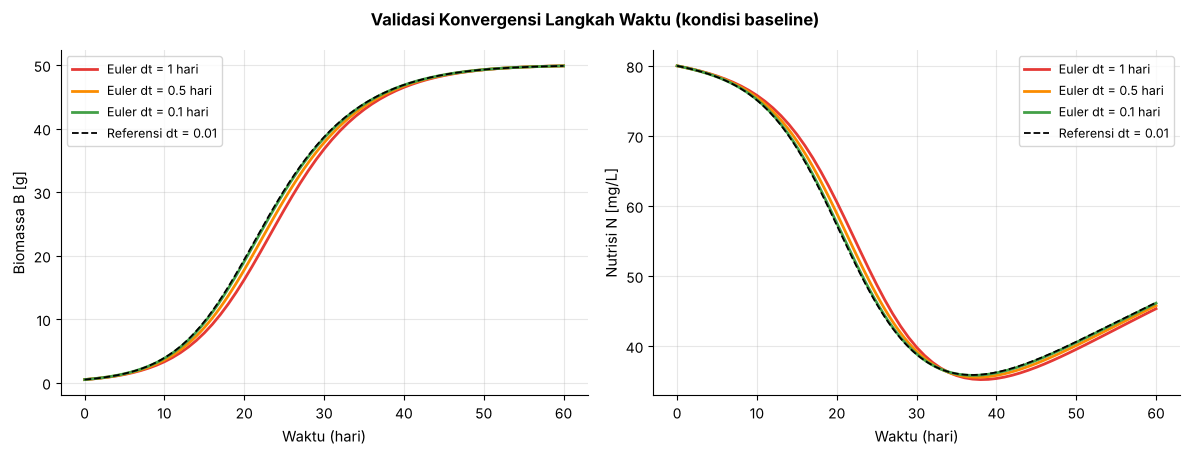

In [23]:
galat = jalankan_validasi(hasil, P)

## 11. Menjalankan Semua dari Awal (Mode Skrip)

Kode pada notebook ini identik dengan file `hidroponik_simulasi.py`. Di komputer lokal:

```bash
pip install -r requirements.txt
python hidroponik_simulasi.py
```
Seluruh grafik tersimpan di folder `figures/` dan tabel ringkasan di `output/ringkasan_skenario.csv`.